In [1]:
import sys
import pandas as pd

import numpy as np
import mvEEG.mvEEG as mvEEG
import mne_bids


import matplotlib.pyplot as plt
plt.rcParams["svg.fonttype"] = "none"

import seaborn as sns 
from os import path

from glob import glob
import json
import tqdm.auto as ta


# while stats are done in JASP, the frequentist results are the same as when done with pingoin, so we use that to add significance markers
import pingouin as pg


%load_ext autoreload
%autoreload 2

In [3]:
ROOT = "../data/derivatives"
DATA_DIR = ROOT
EXPERIMENT_NAME = "banyan2"
bad_epochs = (
    {  # epochs which didn't align with eye tracking for one reason or another, and were excluded during preprocessing
        "05": [737, 739, 740, 741, 745, 746],
        "21": [649, 650, 651, 652],
    }
)

bad_blocks = {
    # blocks for which participants admitted they were confused about the task (normally at the start, or first switch to the other task)
    "17": [6],  # first attention block
    "22": [6, 7, 8, 9],  # was doing SS0 incorrectly for the first few WM blocks
    "32": [6],  # first WM block
}

# participant who came back for a second session. We are going to combine the two sessions.
split_sess_subs = {"22": "34"}

wrangl = mvEEG.Wrangler(
    data_dir=DATA_DIR,
    experiment_name=EXPERIMENT_NAME,
    dropped_chans={},
    t_win=50,
    t_step=25,
    trim_timepoints=[-350, 1200],
    trial_bin_size=15,
    n_folds=2,  # NOTE: _not_ using wrangler n_folds here
)

In [4]:
import json

with open("rejected_subs.json", "r") as f:
    rejected_subs = json.load(f)
rejected_subs

['19', '32', '33']

# Performance on main tasks (WM & Spatial Attention)

In [5]:
def load_behavioral_data(wrangl, isub):
    # get all behavioral files for this subject
    basepath = "/".join(
        str(wrangl.bids_path.copy().update(subject=wrangl.subs[isub], datatype="beh").fpath).split("/")[:-1]
    )
    beh_files = glob(path.join(basepath, "*_data_block*.csv"))

    # load and concatenate behavioral data
    beh = pd.DataFrame()
    for f in beh_files:
        df_block = pd.read_csv(f)
        beh = pd.concat([beh, df_block], axis=0)

    # sort by Block and Trial to ensure proper alignment with EEG epochs
    beh = beh.sort_values(by=["Block", "Trial"]).reset_index(drop=True)

    beh = beh.loc[~(beh.REJ == 1)].reset_index(
        drop=True
    )  # remove real time eye tracking rejects, which aren't in the EEG
    beh = beh.drop(bad_epochs.get(wrangl.subs[isub], [])).reset_index(
        drop=True
    )  # drop bad epochs due to sync errors with eye tracking
    beh = beh.loc[~wrangl.artifacts[isub], :].reset_index(
        drop=True
    )  # drop epochs marked as artifacts during preprocessing

    if wrangl.subs[isub] == "13":
        beh["Subject"] = 13  # fix subject number for sub-13, which was mis-labeled as sub-12 in behavioral data

    return beh


# helper functions to compute K and accuracy by set size for the WM task
def compute_k(accs, changes, ss):
    HR = np.sum(accs * changes) / np.sum(changes)
    FA = np.sum((~accs) * (~changes)) / np.sum(~changes)
    return ss * (HR - FA)


def get_k_by_ss(beh_mem):
    beh_mem.loc[:, "n_targets"] = beh_mem.n_targets.astype(int)  # convert to integers, in case they were strings

    setsizes = sorted(beh_mem.n_targets.unique())
    k_by_ss = {}
    for i, ss in enumerate(setsizes):
        curr_beh = beh_mem.query(f"n_targets=={ss}")
        # get accuracy and change trial info as boolean vectors
        accs = curr_beh.ACC.astype(float).astype(bool).values
        changes = np.array([c == "True" for c in curr_beh["change"].astype(str).values])
        k_by_ss[int(ss)] = compute_k(accs, changes, int(ss))
    return k_by_ss


def get_WM_acc_by_ss(beh_mem):
    beh_mem.loc[:, "n_targets"] = beh_mem.n_targets.astype(int)  # convert to integers, in case they were strings

    setsizes = sorted(beh_mem.n_targets.unique())
    acc_by_ss = {}
    for i, ss in enumerate(setsizes):
        curr_beh = beh_mem.query(f"n_targets=={ss}")
        # get accuracy and change trial info as boolean vectors
        accs = curr_beh.ACC.astype(float).astype(bool).values
        acc_by_ss[int(ss)] = np.mean(accs)
    return acc_by_ss


# helper functions to compute attention probe accuracies and false alarms
def compute_probe_misses(resps):
    n_misses = np.sum(resps == "space")
    n_total = len(resps)
    return n_misses / n_total


def get_probe_misses_by_ss(beh_attn):
    beh_attn = beh_attn[
        beh_attn.relevant_num.notna()
    ].copy()  # keep only trials where a probe number was presented, regardless of during delay or at test (SS0)
    beh_attn.loc[:, "n_targets"] = beh_attn.n_targets.astype(int)  # convert to integers, in case they were strings

    setsizes = sorted(beh_attn.n_targets.unique())
    miss_by_ss = {}
    for i, ss in enumerate(setsizes):
        curr_beh = beh_attn.query(f"n_targets=={ss}")
        resps = curr_beh.RESP.values
        miss_by_ss[int(ss)] = compute_probe_misses(resps)
    return miss_by_ss


def get_probe_accs_by_ss(beh_attn):
    beh_attn = beh_attn[
        beh_attn.relevant_num.notna()
    ].copy()  # keep only trials where a probe number was presented, regardless of during delay or at test (SS0)
    beh_attn = beh_attn.query("RESP != 'space'")  # keep only trials where subject made a response (i.e., didn't miss)
    beh_attn.loc[:, "n_targets"] = beh_attn.n_targets.astype(int)  # convert to integers, in case they were strings

    setsizes = sorted(beh_attn.n_targets.unique())
    acc_by_ss = {}
    for i, ss in enumerate(setsizes):
        curr_beh = beh_attn.query(f"n_targets=={ss}")
        # get accuracy info as boolean vectors
        accs = curr_beh.ACC.astype(float).astype(bool).values
        acc_by_ss[int(ss)] = np.mean(accs)
    return acc_by_ss


def get_probe_FAs_by_ss(beh_attn):
    beh_attn = beh_attn[beh_attn.relevant_num.isna()].copy()  # keep only trials where no probe number was presented
    beh_attn.loc[:, "n_targets"] = beh_attn.n_targets.astype(int)  # convert to integers, in case they were strings

    setsizes = sorted(beh_attn.n_targets.unique())
    fa_by_ss = {}
    for i, ss in enumerate(setsizes):
        curr_beh = beh_attn.query(f"n_targets=={ss}")
        # get false alarm info as boolean vectors
        fas = curr_beh.ACC.astype(float).astype(bool).values
        fa_by_ss[int(ss)] = 1 - np.mean(fas)  # FA rate is 1 - accuracy when no probe is presented
    return fa_by_ss

In [6]:
WM_accs = {}
WM_ks = {}
Attn_probe_accs = {}  # given a probe digit appears and was responded to, was it correctly identified as odd/even
Attn_probe_misses = {}  # given a probe appears, was it missed (i.e., identified as absent when present)
Attn_noProbe_FAs = {}  # given no probe appears, was it incorrectly identified as present

for isub in ta.tqdm(range(wrangl.nsub)):

    if wrangl.subs[isub] in rejected_subs:
        print(f"Skipping {wrangl.subs[isub]} due to rejection in trial counts or behavioral analyses, check notebook 0")
        continue

    # Load the data
    Xdata, _ = wrangl.load_eeg(isub, reject=True)
    beh = load_behavioral_data(wrangl, isub)
    assert Xdata.shape[0] == beh.shape[0], "Mismatch between EEG epochs and behavioral data"
    if wrangl.subs[isub] in bad_blocks:
        keep_blocks = ~beh.Block.isin(bad_blocks[wrangl.subs[isub]])
        beh = beh[keep_blocks].reset_index(drop=True)
        Xdata = Xdata[keep_blocks, :, :]

    if wrangl.subs[isub] in split_sess_subs.keys():
        second_sess_id = split_sess_subs[wrangl.subs[isub]]
        print(f"concatenating {second_sess_id} onto {wrangl.subs[isub]}")
        isub_2nd = np.where([s == second_sess_id for s in wrangl.subs])[0][0]
        Xdata_2nd, _ = wrangl.load_eeg(isub_2nd, reject=True)
        beh_2nd = load_behavioral_data(wrangl, isub_2nd)
        assert Xdata_2nd.shape[0] == beh_2nd.shape[0], "Mismatch between EEG epochs and behavioral data"
        if wrangl.subs[isub_2nd] in bad_blocks:
            keep_blocks = ~beh_2nd.Block.isin(bad_blocks[wrangl.subs[isub_2nd]])
            beh_2nd = beh_2nd[keep_blocks].reset_index(drop=True)
            Xdata_2nd = Xdata_2nd[keep_blocks, :, :]

        beh_2nd.Block += beh.Block.max()  # update block numbers for second session to be continuous with first session
        Xdata = np.concatenate([Xdata, Xdata_2nd], axis=0)
        beh = pd.concat([beh, beh_2nd], axis=0)

    if wrangl.subs[isub] in split_sess_subs.values():
        print(f"Skipping {wrangl.subs[isub]}, was concatenated onto another subject ID")
        continue

    cond_counts = beh.trial_condition.value_counts()
    if min(cond_counts) < 72:
        print(
            f"WARNING ON SUB {wrangl.subs[isub]}: Not enough trials in one or more conditions after bad trial removals"
        )
        print(pd.DataFrame(cond_counts).query("count < 72"))
        continue  # skip the subject entirely

    WM_accs[wrangl.subs[isub]] = get_WM_acc_by_ss(beh.query("block_condition=='memory'"))
    WM_ks[wrangl.subs[isub]] = get_k_by_ss(beh.query("block_condition=='memory'"))
    Attn_probe_accs[wrangl.subs[isub]] = get_probe_accs_by_ss(beh.query("block_condition=='attention'"))
    Attn_probe_misses[wrangl.subs[isub]] = get_probe_misses_by_ss(beh.query("block_condition=='attention'"))
    Attn_noProbe_FAs[wrangl.subs[isub]] = get_probe_FAs_by_ss(beh.query("block_condition=='attention'"))

  0%|          | 0/34 [00:00<?, ?it/s]

Skipping 19 due to rejection in trial counts or behavioral analyses, check notebook 0
concatenating 34 onto 22
Skipping 32 due to rejection in trial counts or behavioral analyses, check notebook 0
Skipping 33 due to rejection in trial counts or behavioral analyses, check notebook 0
Skipping 34, was concatenated onto another subject ID


In [7]:
with open("k_estimates.json", "w") as f:
    json.dump(WM_ks, f)
WM_ks

{'01': {0: np.float64(0.0),
  1: np.float64(1.0),
  2: np.float64(2.0),
  3: np.float64(3.0),
  4: np.float64(3.878787878787879),
  6: np.float64(5.190476190476191),
  8: np.float64(5.631908831908832)},
 '02': {0: np.float64(0.0),
  1: np.float64(1.0),
  2: np.float64(1.8642140468227426),
  3: np.float64(2.531841109709962),
  4: np.float64(3.185185185185185),
  6: np.float64(3.7939110070257613),
  8: np.float64(4.266182698124622)},
 '03': {0: np.float64(0.0),
  1: np.float64(0.9654761904761904),
  2: np.float64(1.8084848484848484),
  3: np.float64(2.53497688751926),
  4: np.float64(2.076190476190476),
  6: np.float64(2.2857142857142856),
  8: np.float64(2.7971014492753623)},
 '04': {0: np.float64(0.0),
  1: np.float64(1.0),
  2: np.float64(2.0),
  3: np.float64(2.4375),
  4: np.float64(1.793564055859138),
  6: np.float64(1.7948560930802202),
  8: np.float64(1.6100313479623818)},
 '05': {0: np.float64(0.0),
  1: np.float64(0.8211875843454791),
  2: np.float64(1.358490566037736),
  3: np

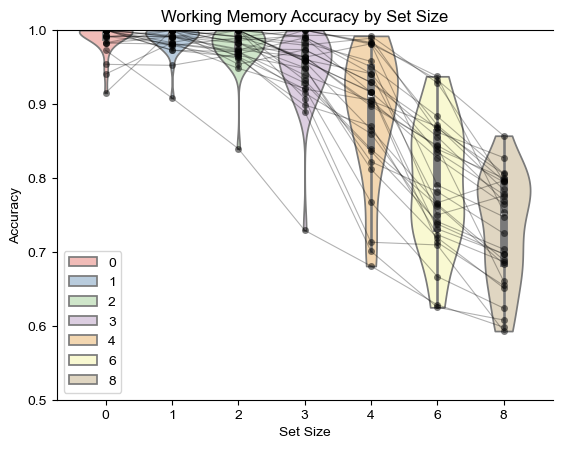

In [8]:
acc_df = (
    pd.DataFrame(WM_accs)
    .reset_index()
    .melt(id_vars=["index"], var_name="Subject", value_name="Accuracy")
    .rename(columns={"index": "Set Size"})
)
ax = sns.violinplot(data=acc_df, x="Set Size", y="Accuracy", cut=0, hue="Set Size", palette="Pastel1")
plt.title("Working Memory Accuracy by Set Size")
ax.set_ylim(0.5, 1)
sns.despine(right=True, top=False)
# plot strip plots of participants at each set size
sns.stripplot(data=acc_df, x="Set Size", y="Accuracy", color="k", alpha=0.5, jitter=False, size=5)

for sub in acc_df.Subject.unique():
    sub_data = acc_df.query(f"Subject=='{sub}'")
    plt.plot(
        [0, 1, 2, 3, 4, 5, 6],  # hack to get the x positions of the violin/strip plots
        sub_data["Accuracy"],
        color="k",
        alpha=0.3,
        linewidth=0.8,
    )

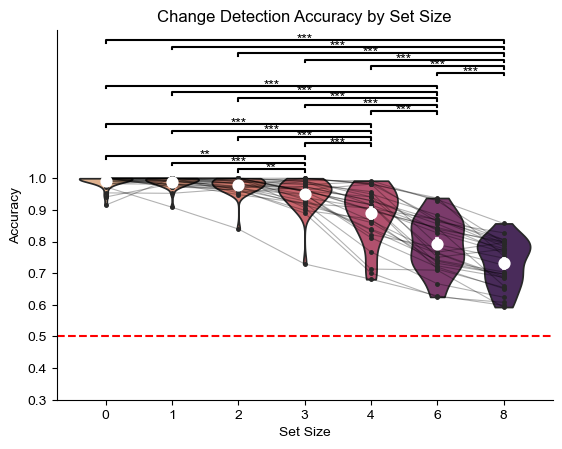

In [9]:
acc_df = (
    pd.DataFrame(WM_accs)
    .reset_index()
    .melt(id_vars=["index"], var_name="Subject", value_name="Accuracy")
    .rename(columns={"index": "Set Size"})
)
ax = sns.violinplot(data=acc_df, x="Set Size", y="Accuracy", cut=0, hue="Set Size", palette="flare", inner="point")
plt.title("Working Memory Accuracy by Set Size")
# ax.set_ylim(0.5, 1)
# sns.despine(right=True, top=False)

# plot lines connecting each participant across each set size
for sub in acc_df.Subject.unique():
    sub_data = acc_df.query(f"Subject=='{sub}'")
    plt.plot(
        [0, 1, 2, 3, 4, 5, 6],  # hack to get the x positions of the violin/strip plots
        sub_data["Accuracy"],
        color="k",
        alpha=0.3,
        linewidth=0.8,
    )

_ = sns.pointplot(data=acc_df, x="Set Size", y="Accuracy", color="w", linestyle="none", zorder=100, errorbar="se")

acc_ttests_res = pg.pairwise_tests(data=acc_df, dv="Accuracy", within="Set Size", subject="Subject", padjust="bonf")

loc_map = {0: 0, 1: 1, 2: 2, 3: 3, 4: 4, 6: 5, 8: 6}

# significant pairwise comparisons
sig_df = acc_ttests_res.loc[acc_ttests_res["p-corr"] < 0.05, ["A", "B", "p-corr"]].copy()
sig_df["A"] = sig_df["A"].astype(int)
sig_df["B"] = sig_df["B"].astype(int)
sig_df["x1"] = sig_df["A"].map(loc_map)
sig_df["x2"] = sig_df["B"].map(loc_map)
sig_df = sig_df.dropna(subset=["x1", "x2"]).copy()

sig_df[["x1", "x2"]] = np.sort(sig_df[["x1", "x2"]].values, axis=1)
sig_df["left"] = sig_df["x1"]
sig_df["right"] = sig_df["x2"]

right_order = sorted(sig_df["right"].unique())
sig_df["level"] = np.nan
next_base_level = 0
for r in right_order:
    idx = sig_df.index[sig_df["right"] == r]
    idx_sorted = sig_df.loc[idx].sort_values("left", ascending=False).index.tolist()
    for j, row_idx in enumerate(idx_sorted):
        sig_df.loc[row_idx, "level"] = next_base_level + j
    next_base_level += len(idx_sorted) + 1
sig_df["level"] = sig_df["level"].astype(int)

y_min, y_max = acc_df["Accuracy"].min(), acc_df["Accuracy"].max()
y_range = y_max - y_min if y_max > y_min else 1.0
y_base = y_max + 0.05 * y_range
level_step = 0.05 * y_range
h = 0.02 * y_range

for _, row in sig_df.iterrows():
    x1, x2 = row["x1"], row["x2"]
    y = y_base + row["level"] * level_step
    p_val = row["p-corr"]

    ax.plot([x1, x1, x2, x2], [y, y + h, y + h, y], lw=1.5, c="k")
    sig = "***" if p_val < 0.001 else "**" if p_val < 0.01 else "*"
    ax.text((x1 + x2) / 2, y - 0.01, sig, ha="center", va="bottom", color="k")

_ = plt.axhline(0.5, color="r", linestyle="--", zorder=-1)
plt.title("Change Detection Accuracy by Set Size")
plt.legend([], [], frameon=False)
sns.despine(right=True, top=True)

if len(sig_df) > 0:
    top_y = y_base + sig_df["level"].max() * level_step + h
    ax.set_ylim(y_min - 0.02 * y_range, top_y + 0.08 * y_range)

ax.set_yticks([0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0])
plt.savefig("figures/behavior_change_detection_accuracy_by_setsize.png", dpi=300, bbox_inches="tight", transparent=True)

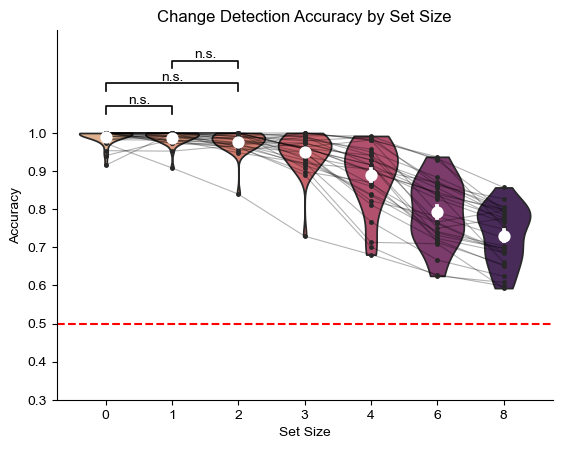

In [55]:
loc_map = {0: 0, 1: 1, 2: 2, 3: 3, 4: 4, 6: 5, 8: 6}

ax = sns.violinplot(
    data=acc_df,
    x="Set Size",
    y="Accuracy",
    cut=0,
    hue="Set Size",
    palette="flare",
    inner="point",
)

for sub, sub_data in acc_df.groupby("Subject"):
    sub_data = sub_data.sort_values("Set Size")
    xvals = sub_data["Set Size"].map(loc_map)
    ax.plot(xvals, sub_data["Accuracy"], color="k", alpha=0.3, linewidth=0.8)

sns.pointplot(
    data=acc_df,
    x="Set Size",
    y="Accuracy",
    color="w",
    linestyle="none",
    zorder=100,
    errorbar="se",
)

ns_df = acc_ttests_res.loc[acc_ttests_res["p-corr"] > 0.05, ["A", "B", "p-corr"]].copy()

ns_df["x1"] = ns_df["A"].astype(int).map(loc_map)
ns_df["x2"] = ns_df["B"].astype(int).map(loc_map)
ns_df = ns_df.dropna(subset=["x1", "x2"]).copy()

ns_df[["x1", "x2"]] = np.sort(ns_df[["x1", "x2"]].values, axis=1)
ns_df["level"] = range(len(ns_df))

y_min = acc_df["Accuracy"].min()
y_max = acc_df["Accuracy"].max()
y_range = max(y_max - y_min, 1.0)
y_base = y_max + 0.05 * y_range
level_step = 0.06 * y_range
h = 0.02 * y_range

for _, row in ns_df.iterrows():
    x1, x2 = row["x1"], row["x2"]
    y = y_base + row["level"] * level_step

    ax.plot([x1, x1, x2, x2], [y, y + h, y + h, y], color="k", lw=1.2)
    ax.text(
        (x1 + x2) / 2,
        y + h,
        "n.s.",
        ha="center",
        va="bottom",
        color="k",
    )

ax.axhline(0.5, color="r", linestyle="--", zorder=-1)
ax.set_title("Change Detection Accuracy by Set Size")
ax.legend([], [], frameon=False)
sns.despine(right=True, top=True)

if not ns_df.empty:
    top_y = y_base + ns_df["level"].max() * level_step + h
    ax.set_ylim(y_min - 0.02 * y_range, top_y + 0.08 * y_range)

ax.set_yticks([0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0])
plt.savefig(
    "figures/behavior_change_detection_accuracy_by_setsize_ns.png",
    dpi=300,
    bbox_inches="tight",
    transparent=True,
)

In [11]:
acc_df.to_csv("behavior_files/WM_acc_by_ss.csv", index=False)

acc_df.pivot(index="Subject", columns="Set Size", values="Accuracy").to_csv(
    "behavior_files/WM_acc_by_ss_pivot.csv", index=True
)

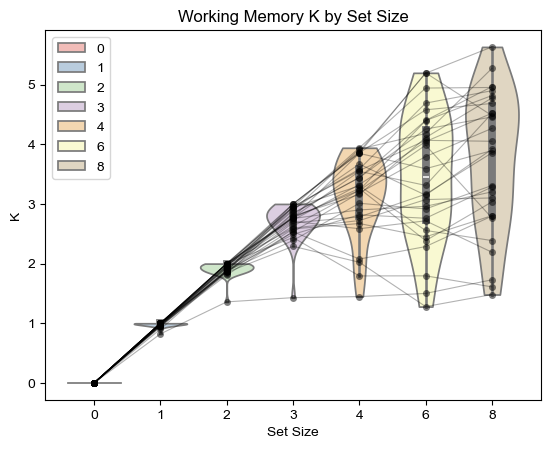

In [12]:
k_df = (
    pd.DataFrame(WM_ks)
    .reset_index()
    .melt(id_vars=["index"], var_name="Subject", value_name="K")
    .rename(columns={"index": "Set Size"})
)
ax = sns.violinplot(data=k_df, x="Set Size", y="K", cut=0, hue="Set Size", palette="Pastel1")

plt.title("Working Memory K by Set Size")
_ = sns.stripplot(data=k_df, x="Set Size", y="K", color="k", alpha=0.5, jitter=False, size=5)
# add a line per participant
for sub in k_df.Subject.unique():
    sub_data = k_df.query(f"Subject=='{sub}'")
    plt.plot(
        [0, 1, 2, 3, 4, 5, 6],  # hack to get the x positions of the violin/strip plots
        sub_data["K"],
        color="k",
        alpha=0.3,
        linewidth=0.8,
    )

In [13]:
k_df[k_df["Set Size"] > 0].to_csv("behavior_files/WM_k_by_ss_minus0.csv", index=False)

In [14]:
k_df[k_df["Set Size"] > 0].pivot(index="Subject", columns="Set Size", values="K").to_csv(
    "behavior_files/WM_k_by_ss_minus0_pivot.csv", index=True
)

In [15]:
aov_res = pg.rm_anova(data=k_df[k_df["Set Size"] > 0], dv="K", within="Set Size", subject="Subject")
aov_res

,Source,ddof1,ddof2,F,p-unc,p-GG-corr,ng2,eps,sphericity,W-spher,p-spher
0,Set Size,5,145,111.119568,8.549523e-48,7.150174e-15,0.649777,0.275169,False,0.000178,1.566158e-41


In [16]:
ttests_res = pg.pairwise_tests(
    data=k_df[k_df["Set Size"] > 0], dv="K", within="Set Size", subject="Subject", padjust="bonf"
)
ttests_res

,Contrast,A,B,Paired,Parametric,T,dof,alternative,p-unc,p-corr,p-adjust,BF10,hedges
0,Set Size,1,2,True,True,-55.930183,29.0,two-sided,4.303201e-31,6.454801e-30,bonf,3.644e+27,-10.339230
1,Set Size,1,3,True,True,-33.304739,29.0,two-sided,1.152941e-24,1.729411e-23,bonf,2.303e+21,-7.752312
2,Set Size,1,4,True,True,-18.496062,29.0,two-sided,1.350720e-17,2.026080e-16,bonf,3.636e+14,-4.587308
3,Set Size,1,6,True,True,-12.853819,29.0,two-sided,1.675611e-13,2.513416e-12,bonf,4.375e+10,-3.239580
4,Set Size,1,8,True,True,-13.194612,29.0,two-sided,8.733624e-14,1.310044e-12,bonf,8.149e+10,-3.333035
5,Set Size,2,3,True,True,-19.093883,29.0,two-sided,5.745934e-18,8.618900e-17,bonf,8.261e+14,-3.323761
6,Set Size,2,4,True,True,-11.184631,29.0,two-sided,4.907679e-12,7.361518e-11,bonf,1.751e+09,-2.561984
7,Set Size,2,6,True,True,-8.183889,29.0,two-sided,5.042531e-09,7.563796e-08,bonf,2.47e+06,-2.007249
8,Set Size,2,8,True,True,-8.865745,29.0,two-sided,9.409534e-10,1.411430e-08,bonf,1.202e+07,-2.187190
9,Set Size,3,4,True,True,-5.505935,29.0,two-sided,6.223728e-06,9.335592e-05,bonf,3263.539,-0.842032


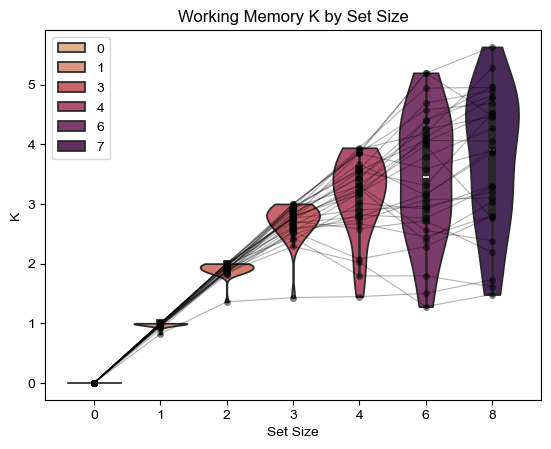

In [17]:
k_df = (
    pd.DataFrame(WM_ks)
    .reset_index()
    .melt(id_vars=["index"], var_name="Subject", value_name="K")
    .rename(columns={"index": "Set Size"})
)

ax = sns.violinplot(data=k_df, x="Set Size", y="K", cut=0, hue="Set Size", palette="flare")
plt.title("Working Memory K by Set Size")
_ = sns.stripplot(data=k_df, x="Set Size", y="K", color="k", alpha=0.5, jitter=False, size=5)

# add a line per participant
for sub in k_df.Subject.unique():
    sub_data = k_df.query(f"Subject=='{sub}'")
    plt.plot(
        [0, 1, 2, 3, 4, 5, 6],  # x positions of the violin/strip plots
        sub_data["K"],
        color="k",
        alpha=0.3,
        linewidth=0.8,
    )

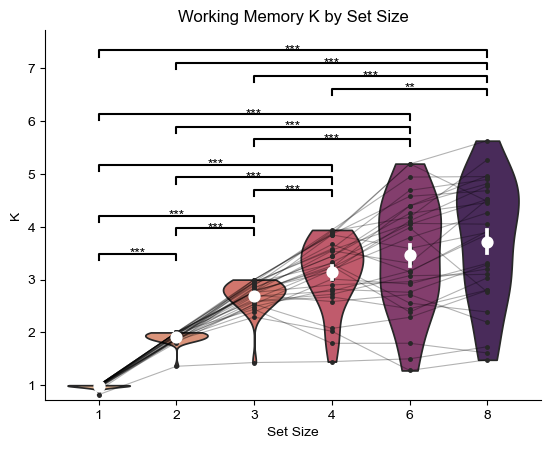

In [18]:
k_df = (
    pd.DataFrame(WM_ks)
    .reset_index()
    .melt(id_vars=["index"], var_name="Subject", value_name="K")
    .rename(columns={"index": "Set Size"})
).query("`Set Size` > 0")

ax = sns.violinplot(data=k_df, x="Set Size", y="K", cut=0, hue="Set Size", palette="flare", inner="point")
plt.title("Working Memory K by Set Size")
# _ = sns.stripplot(data=k_df, x="Set Size", y="K", color="k", alpha=0.5, jitter=False, size=5)

# add a line per participant
for sub in k_df.Subject.unique():
    sub_data = k_df.query(f"Subject=='{sub}'")
    plt.plot(
        [0, 1, 2, 3, 4, 5],  # x positions of the violin/strip plots
        sub_data["K"],
        color="k",
        alpha=0.3,
        linewidth=0.8,
    )

_ = sns.pointplot(data=k_df, x="Set Size", y="K", color="w", linestyle="none", zorder=100, errorbar="se")

# map set sizes to x-axis locations
loc_map = {
    1: 0,
    2: 1,
    3: 2,
    4: 3,
    6: 4,
    8: 5,
}

# keep only significant comparisons and convert to plotting coordinates
sig_df = ttests_res.loc[ttests_res["p-corr"] < 0.05, ["A", "B", "p-corr"]].copy()
sig_df["x1"] = sig_df["A"].map(loc_map)
sig_df["x2"] = sig_df["B"].map(loc_map)
sig_df = sig_df.dropna(subset=["x1", "x2"]).copy()

# ensure left-to-right ordering for interval logic
sig_df[["x1", "x2"]] = np.sort(sig_df[["x1", "x2"]].values, axis=1)
sig_df["left"] = sig_df["x1"]
sig_df["right"] = sig_df["x2"]

# stack by highest compared set size (right endpoint),
# and within each endpoint, shorter comparisons lower and wider ones above.
right_order = sorted(sig_df["right"].unique())
sig_df["level"] = np.nan
next_base_level = 0

for r in right_order:
    idx = sig_df.index[sig_df["right"] == r]
    # larger left endpoint -> shorter span -> lower
    idx_sorted = sig_df.loc[idx].sort_values("left", ascending=False).index.tolist()
    for j, row_idx in enumerate(idx_sorted):
        sig_df.loc[row_idx, "level"] = next_base_level + j

    # move to a fresh vertical band so different right-endpoint groups never overlap
    next_base_level += len(idx_sorted) + 1

sig_df["level"] = sig_df["level"].astype(int)

# data-driven y placement so bars never sit on top of the violins
y_min, y_max = k_df["K"].min(), k_df["K"].max()
y_range = y_max - y_min if y_max > y_min else 1.0
y_base = y_max + 0.05 * y_range - 2.5
level_step = 0.05 * y_range
h = 0.025 * y_range

# draw bars + significance text
for _, row in sig_df.iterrows():
    x1, x2 = row["x1"], row["x2"]
    y = y_base + row["level"] * level_step
    p_val = row["p-corr"]
    col = "k"

    ax.plot([x1, x1, x2, x2], [y, y + h, y + h, y], lw=1.5, c=col)

    if p_val < 0.001:
        sig = "***"
    elif p_val < 0.01:
        sig = "**"
    elif p_val < 0.05:
        sig = "*"
    else:
        sig = "ns"

    ax.text((x1 + x2) / 2, y, sig, ha="center", va="bottom", color=col)

# expand y-limits to include the highest bracket
if len(sig_df) > 0:
    top_y = y_base + sig_df["level"].max() * level_step + h
    ax.set_ylim(y_min - 0.02 * y_range, top_y + 0.08 * y_range)

plt.legend([], [], frameon=False)  # remove legend
sns.despine(right=True, top=True)
plt.savefig("figures/behavior_WM_k_by_setsize.png", dpi=300, bbox_inches="tight", transparent=True)

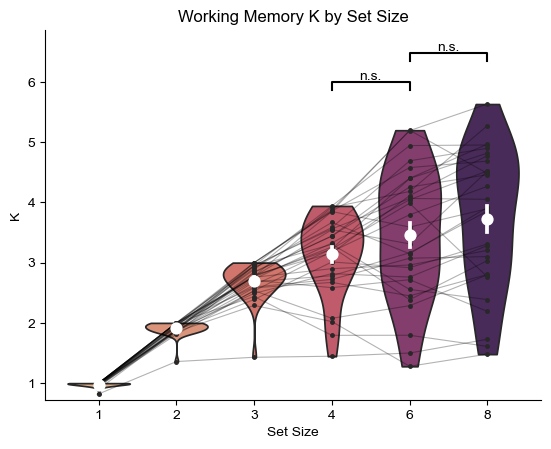

In [19]:
k_df = (
    pd.DataFrame(WM_ks)
    .reset_index()
    .melt(id_vars=["index"], var_name="Subject", value_name="K")
    .rename(columns={"index": "Set Size"})
).query("`Set Size` > 0")

ax = sns.violinplot(
    data=k_df,
    x="Set Size",
    y="K",
    cut=0,
    hue="Set Size",
    palette="flare",
    inner="point",
)

for sub in k_df.Subject.unique():
    sub_data = k_df.query(f"Subject=='{sub}'").sort_values("Set Size")
    ax.plot(
        range(len(sub_data)),
        sub_data["K"],
        color="k",
        alpha=0.3,
        linewidth=0.8,
    )

sns.pointplot(
    data=k_df,
    x="Set Size",
    y="K",
    color="w",
    linestyle="none",
    zorder=100,
    errorbar="se",
)

loc_map = {1: 0, 2: 1, 3: 2, 4: 3, 6: 4, 8: 5}

# Keep only non-significant comparisons
ns_df = ttests_res.loc[ttests_res["p-corr"] > 0.05, ["A", "B", "p-corr"]].copy()

ns_df["x1"] = ns_df["A"].astype(int).map(loc_map)
ns_df["x2"] = ns_df["B"].astype(int).map(loc_map)
ns_df = ns_df.dropna(subset=["x1", "x2"]).copy()

ns_df[["x1", "x2"]] = np.sort(ns_df[["x1", "x2"]].values, axis=1)
ns_df["left"] = ns_df["x1"]
ns_df["right"] = ns_df["x2"]

# Stack bars by right endpoint
ns_df["level"] = np.nan
next_base_level = 0

for right in sorted(ns_df["right"].unique()):
    idx = ns_df.index[ns_df["right"] == right]
    idx_sorted = ns_df.loc[idx].sort_values("left", ascending=False).index

    for level, row_idx in enumerate(idx_sorted):
        ns_df.loc[row_idx, "level"] = next_base_level + level

    next_base_level += len(idx_sorted) + 1

ns_df["level"] = ns_df["level"].astype(int)

y_min, y_max = k_df["K"].min(), k_df["K"].max()
y_range = y_max - y_min if y_max > y_min else 1.0
y_base = y_max + 0.05 * y_range
level_step = 0.05 * y_range
h = 0.025 * y_range

for _, row in ns_df.iterrows():
    x1, x2 = row["x1"], row["x2"]
    y = y_base + row["level"] * level_step

    ax.plot(
        [x1, x1, x2, x2],
        [y, y + h, y + h, y],
        lw=1.5,
        color="k",
    )
    ax.text(
        (x1 + x2) / 2,
        y + h,
        "n.s.",
        ha="center",
        va="bottom",
        color="k",
    )

if not ns_df.empty:
    top_y = y_base + ns_df["level"].max() * level_step + h
    ax.set_ylim(y_min - 0.02 * y_range, top_y + 0.08 * y_range)

plt.title("Working Memory K by Set Size")
plt.legend([], [], frameon=False)
sns.despine(right=True, top=True)
plt.savefig(
    "figures/behavior_WM_k_by_setsize_ns.png",
    dpi=300,
    bbox_inches="tight",
    transparent=True,
)

In [20]:
mean_k_ss_greater_than_3 = k_df[k_df["Set Size"] > 3].groupby("Set Size")["K"].mean().mean()

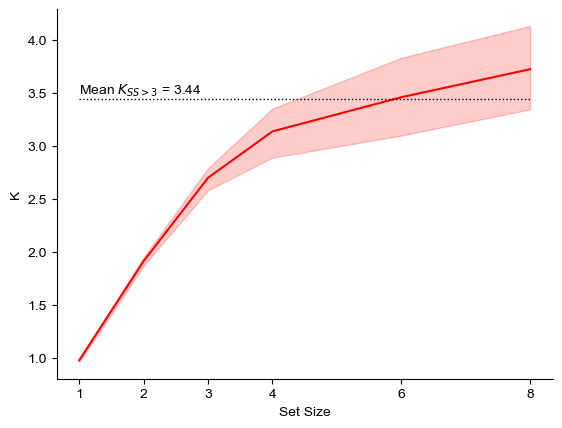

In [21]:
ax = sns.lineplot(data=k_df[k_df["Set Size"] > 0], x="Set Size", y="K", color="red", legend=False)
sns.despine(right=True, top=True)
_ = ax.set_xticks([1, 2, 3, 4, 6, 8])
_ = ax.hlines(y=mean_k_ss_greater_than_3, xmin=1, xmax=8, color="k", linestyle=":", lw=1)
# on the left end, state that the average K for set sizes greater than 3 is around mean_k_ss_greater_than_3
mean_str = f"{mean_k_ss_greater_than_3:.2f}"
_ = ax.text(1, mean_k_ss_greater_than_3 + 0.01, r"Mean $K_{SS>3}$ = " + mean_str, ha="left", va="bottom")
plt.savefig("figures/WM_K_by_set_size.png", dpi=300, bbox_inches="tight", transparent=True)

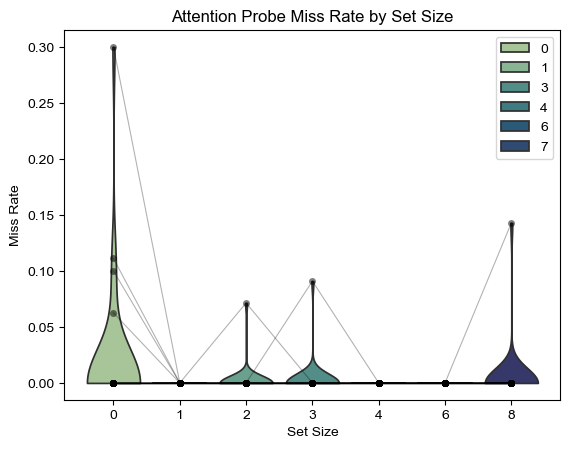

In [22]:
probe_misses_df = (
    pd.DataFrame(Attn_probe_misses)
    .reset_index()
    .melt(id_vars=["index"], var_name="Subject", value_name="Miss Rate")
    .rename(columns={"index": "Set Size"})
)
ax = sns.violinplot(data=probe_misses_df, x="Set Size", y="Miss Rate", cut=0, hue="Set Size", palette="crest")
plt.title("Attention Probe Miss Rate by Set Size")
_ = sns.stripplot(data=probe_misses_df, x="Set Size", y="Miss Rate", color="k", alpha=0.5, jitter=False, size=5)
for sub in probe_misses_df.Subject.unique():
    sub_data = probe_misses_df.query(f"Subject=='{sub}'")
    plt.plot(
        [0, 1, 2, 3, 4, 5, 6],  # hack to get the x positions of the violin/strip plots
        sub_data["Miss Rate"],
        color="k",
        alpha=0.3,
        linewidth=0.8,
    )
plt.savefig("figures/Attn_probe_miss_rate_by_set_size.png", dpi=300, bbox_inches="tight", transparent=True)

In [23]:
probe_misses_df[probe_misses_df["Miss Rate"] > 0.05]

,Set Size,Subject,Miss Rate
21,0,04,0.300000
94,3,14,0.090909
98,0,15,0.062500
132,8,20,0.142857
156,2,25,0.071429
161,0,26,0.111111
196,0,35,0.100000


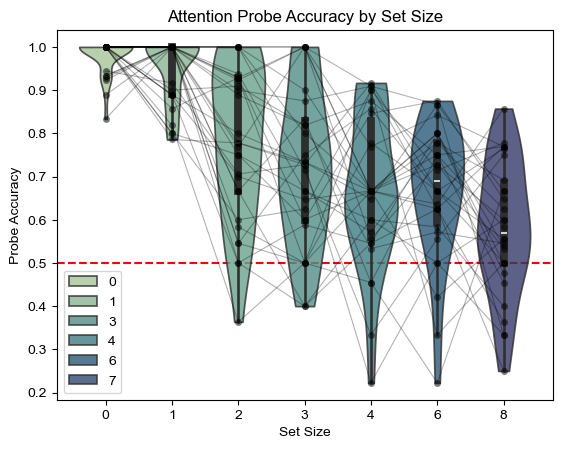

In [24]:
probe_accs_df = (
    pd.DataFrame(Attn_probe_accs)
    .reset_index()
    .melt(id_vars=["index"], var_name="Subject", value_name="Probe Accuracy")
    .rename(columns={"index": "Set Size"})
)
ax = sns.violinplot(
    data=probe_accs_df, x="Set Size", y="Probe Accuracy", cut=0, hue="Set Size", palette="crest", alpha=0.8
)
plt.title("Attention Probe Accuracy by Set Size")
_ = sns.stripplot(data=probe_accs_df, x="Set Size", y="Probe Accuracy", color="k", alpha=0.5, jitter=False, size=5)
for sub in probe_accs_df.Subject.unique():
    sub_data = probe_accs_df.query(f"Subject=='{sub}'")
    plt.plot(
        [0, 1, 2, 3, 4, 5, 6],  # hack to get the x positions of the violin/strip plots
        sub_data["Probe Accuracy"],
        color="k",
        alpha=0.3,
        linewidth=0.8,
    )
_ = plt.axhline(0.5, color="r", linestyle="--", label="Chance Level", zorder=-1)

In [25]:
probe_accs_df.to_csv("behavior_files/Attn_probe_acc_by_ss.csv", index=False)

In [26]:
probe_accs_df.pivot(index="Subject", columns="Set Size", values="Probe Accuracy").to_csv(
    "behavior_files/Attn_probe_acc_by_ss_pivot.csv", index=True
)

/opt/homebrew/Caskroom/miniforge/base/envs/preproc_pype/lib/python3.12/site-packages/pingouin/pairwise.py:28: UserWarning: pairwise_ttests is deprecated, use pairwise_tests instead.
  warnings.warn("pairwise_ttests is deprecated, use pairwise_tests instead.", UserWarning)


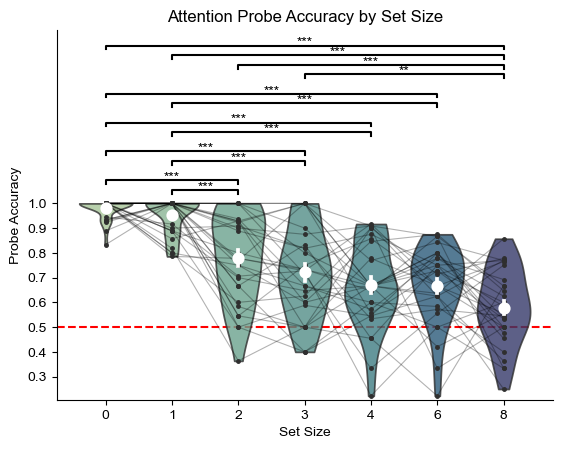

In [27]:
probe_ttests_res = pg.pairwise_ttests(
    data=probe_accs_df,
    dv="Probe Accuracy",
    within="Set Size",
    subject="Subject",
    padjust="bonf",
)

ax = sns.violinplot(
    data=probe_accs_df,
    x="Set Size",
    y="Probe Accuracy",
    cut=0,
    hue="Set Size",
    palette="crest",
    alpha=0.8,
    inner="point",
)
# _ = sns.stripplot(
#     data=probe_accs_df,
#     x="Set Size",
#     y="Probe Accuracy",
#     color="k",
#     alpha=0.5,
#     jitter=False,
#     size=5,
# )

loc_map = {0: 0, 1: 1, 2: 2, 3: 3, 4: 4, 6: 5, 8: 6}

for sub in probe_accs_df["Subject"].unique():
    sub_data = probe_accs_df.query(f"Subject=='{sub}'").sort_values("Set Size")
    xvals = sub_data["Set Size"].map(loc_map).values
    plt.plot(xvals, sub_data["Probe Accuracy"].values, color="k", alpha=0.3, linewidth=0.8)

_ = sns.pointplot(
    data=probe_accs_df,
    x="Set Size",
    y="Probe Accuracy",
    color="w",
    linestyle="none",
    zorder=100,
    errorbar="se",
)

# significant pairwise comparisons
sig_df = probe_ttests_res.loc[probe_ttests_res["p-corr"] < 0.05, ["A", "B", "p-corr"]].copy()
sig_df["A"] = sig_df["A"].astype(int)
sig_df["B"] = sig_df["B"].astype(int)
sig_df["x1"] = sig_df["A"].map(loc_map)
sig_df["x2"] = sig_df["B"].map(loc_map)
sig_df = sig_df.dropna(subset=["x1", "x2"]).copy()

sig_df[["x1", "x2"]] = np.sort(sig_df[["x1", "x2"]].values, axis=1)
sig_df["left"] = sig_df["x1"]
sig_df["right"] = sig_df["x2"]

right_order = sorted(sig_df["right"].unique())
sig_df["level"] = np.nan
next_base_level = 0
for r in right_order:
    idx = sig_df.index[sig_df["right"] == r]
    idx_sorted = sig_df.loc[idx].sort_values("left", ascending=False).index.tolist()
    for j, row_idx in enumerate(idx_sorted):
        sig_df.loc[row_idx, "level"] = next_base_level + j
    next_base_level += len(idx_sorted) + 1
sig_df["level"] = sig_df["level"].astype(int)

y_min, y_max = probe_accs_df["Probe Accuracy"].min(), probe_accs_df["Probe Accuracy"].max()
y_range = y_max - y_min if y_max > y_min else 1.0
y_base = y_max + 0.05 * y_range
level_step = 0.05 * y_range
h = 0.02 * y_range

for _, row in sig_df.iterrows():
    x1, x2 = row["x1"], row["x2"]
    y = y_base + row["level"] * level_step
    p_val = row["p-corr"]

    ax.plot([x1, x1, x2, x2], [y, y + h, y + h, y], lw=1.5, c="k")
    sig = "***" if p_val < 0.001 else "**" if p_val < 0.01 else "*"
    ax.text((x1 + x2) / 2, y + 0.001, sig, ha="center", va="bottom", color="k")

_ = plt.axhline(0.5, color="r", linestyle="--", zorder=-1)
plt.title("Attention Probe Accuracy by Set Size")
plt.legend([], [], frameon=False)
sns.despine(right=True, top=True)

if len(sig_df) > 0:
    top_y = y_base + sig_df["level"].max() * level_step + h
    ax.set_ylim(y_min - 0.02 * y_range, top_y + 0.08 * y_range)

ax.set_yticks([0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0])
plt.savefig("figures/behavior_attention_probe_accuracy_by_setsize.png", dpi=300, bbox_inches="tight", transparent=True)

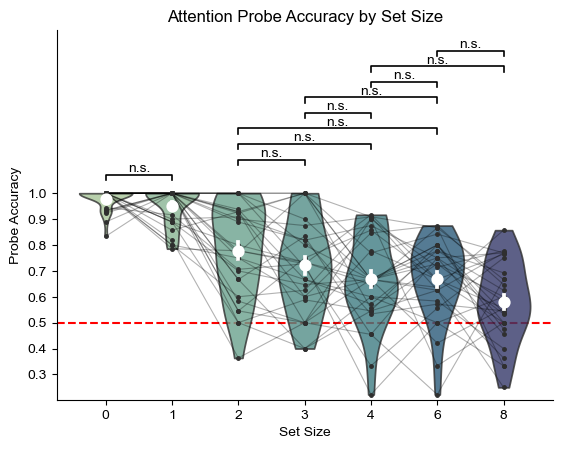

In [28]:
# Plot attention probe accuracy with non-significant comparisons labeled "n.s."

loc_map = {0: 0, 1: 1, 2: 2, 3: 3, 4: 4, 6: 5, 8: 6}

ax = sns.violinplot(
    data=probe_accs_df,
    x="Set Size",
    y="Probe Accuracy",
    cut=0,
    hue="Set Size",
    palette="crest",
    alpha=0.8,
    inner="point",
)

for sub, sub_data in probe_accs_df.groupby("Subject"):
    sub_data = sub_data.sort_values("Set Size")
    xvals = sub_data["Set Size"].map(loc_map)
    ax.plot(xvals, sub_data["Probe Accuracy"], color="k", alpha=0.3, linewidth=0.8)

sns.pointplot(
    data=probe_accs_df,
    x="Set Size",
    y="Probe Accuracy",
    color="w",
    linestyle="none",
    zorder=100,
    errorbar="se",
)

sig_df = probe_ttests_res.loc[probe_ttests_res["p-corr"] > 0.05, ["A", "B", "p-corr"]].copy()

sig_df["x1"] = sig_df["A"].astype(int).map(loc_map)
sig_df["x2"] = sig_df["B"].astype(int).map(loc_map)
sig_df = sig_df.dropna(subset=["x1", "x2"])

sig_df[["x1", "x2"]] = np.sort(sig_df[["x1", "x2"]].values, axis=1)
sig_df["level"] = range(len(sig_df))

y_min = probe_accs_df["Probe Accuracy"].min()
y_max = probe_accs_df["Probe Accuracy"].max()
y_range = max(y_max - y_min, 1.0)
y_base = y_max + 0.05 * y_range
level_step = 0.06 * y_range
h = 0.02 * y_range

for _, row in sig_df.iterrows():
    x1, x2 = row["x1"], row["x2"]
    y = y_base + row["level"] * level_step

    ax.plot([x1, x1, x2, x2], [y, y + h, y + h, y], color="k", lw=1.2)
    ax.text((x1 + x2) / 2, y + h, "n.s.", ha="center", va="bottom", color="k")

ax.axhline(0.5, color="r", linestyle="--", zorder=-1)
ax.set_title("Attention Probe Accuracy by Set Size")
ax.legend([], [], frameon=False)
sns.despine(right=True, top=True)

if not sig_df.empty:
    top_y = y_base + sig_df["level"].max() * level_step + h
    ax.set_ylim(y_min - 0.02 * y_range, top_y + 0.08 * y_range)

ax.set_yticks([0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0])
plt.savefig(
    "figures/behavior_attention_probe_accuracy_by_setsize_ns.png",
    dpi=300,
    bbox_inches="tight",
    transparent=True,
)

In [29]:
probe_ttests_res

,Contrast,A,B,Paired,Parametric,T,dof,alternative,p-unc,p-corr,p-adjust,BF10,hedges
0,Set Size,0,1,True,True,1.609540,29.0,two-sided,1.183316e-01,1.000000e+00,bonf,0.616,0.456109
1,Set Size,0,2,True,True,6.205501,29.0,two-sided,9.077907e-07,1.906361e-05,bonf,1.929e+04,1.514618
2,Set Size,0,3,True,True,8.527566,29.0,two-sided,2.147153e-09,4.509022e-08,bonf,5.519e+06,1.941327
3,Set Size,0,4,True,True,9.616871,29.0,two-sided,1.589143e-10,3.337201e-09,bonf,6.456e+07,2.397374
4,Set Size,0,6,True,True,10.424839,29.0,two-sided,2.546607e-11,5.347876e-10,bonf,3.663e+08,2.669473
5,Set Size,0,8,True,True,14.141618,29.0,two-sided,1.520379e-14,3.192796e-13,bonf,4.331e+11,3.512515
6,Set Size,1,2,True,True,5.512920,29.0,two-sided,6.104434e-06,1.281931e-04,bonf,3322.106,1.236130
7,Set Size,1,3,True,True,6.678367,29.0,two-sided,2.523824e-07,5.300031e-06,bonf,6.336e+04,1.641689
8,Set Size,1,4,True,True,7.641913,29.0,two-sided,1.998818e-08,4.197519e-07,bonf,6.775e+05,2.062961
9,Set Size,1,6,True,True,8.995033,29.0,two-sided,6.891565e-10,1.447229e-08,bonf,1.612e+07,2.270382


In [30]:
# for each set size, test whether probe accuracy is above chance (0.5) using a one-sample t-test
for ss in sorted(probe_accs_df["Set Size"].unique()):
    ss_data = probe_accs_df[probe_accs_df["Set Size"] == ss]["Probe Accuracy"].values
    ttest_res = pg.ttest(ss_data, 0.5, alternative="greater")
    print(f"Set Size {ss}: t={ttest_res.loc['T-test', 'T']:.3f}, p={ttest_res.loc['T-test', 'p-val']:.4f}")

Set Size 0: t=62.930, p=0.0000
Set Size 1: t=33.011, p=0.0000
Set Size 2: t=8.430, p=0.0000
Set Size 3: t=6.671, p=0.0000
Set Size 4: t=5.240, p=0.0000
Set Size 6: t=5.814, p=0.0000
Set Size 8: t=2.828, p=0.0042


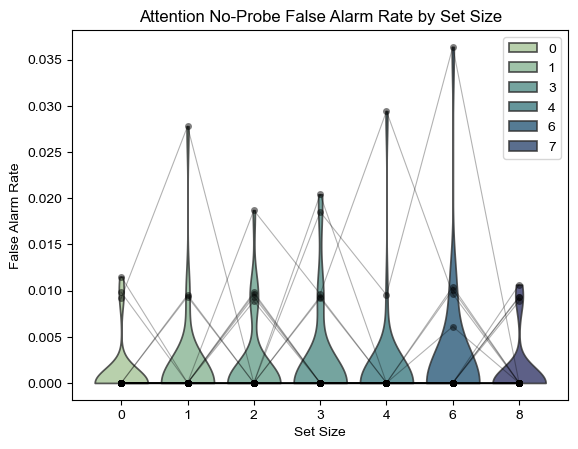

In [31]:
probe_FAs_df = (
    pd.DataFrame(Attn_noProbe_FAs)
    .reset_index()
    .melt(id_vars=["index"], var_name="Subject", value_name="False Alarm Rate")
    .rename(columns={"index": "Set Size"})
)
ax = sns.violinplot(
    data=probe_FAs_df, x="Set Size", y="False Alarm Rate", cut=0, hue="Set Size", palette="crest", alpha=0.8
)
plt.title("Attention No-Probe False Alarm Rate by Set Size")
_ = sns.stripplot(data=probe_FAs_df, x="Set Size", y="False Alarm Rate", color="k", alpha=0.5, jitter=False, size=5)
for sub in probe_FAs_df.Subject.unique():
    sub_data = probe_FAs_df.query(f"Subject=='{sub}'")
    plt.plot(
        [0, 1, 2, 3, 4, 5, 6],  # hack to get the x positions of the violin/strip plots
        sub_data["False Alarm Rate"],
        color="k",
        alpha=0.3,
        linewidth=0.8,
    )
plt.savefig("figures/behavior_attention_noProbe_FA_by_setsize.png", dpi=300, bbox_inches="tight", transparent=True)

# Correlating Spatial Attention Accuracy and WM K performance

In [32]:
sub_ks = k_df[k_df["Set Size"] > 3].groupby("Subject")["K"].mean()
sub_ks

Subject
01    4.900391
02    3.748426
03    2.386335
04    1.732817
05    1.558493
06    2.497469
07    3.577476
08    3.021303
09    4.457212
10    1.594584
11    3.078956
12    3.963898
13    3.267796
14    4.015886
15    4.148232
16    4.373082
17    3.792024
18    3.892161
20    4.269283
21    4.390433
22    4.612015
23    4.509983
25    2.954153
26    2.641373
27    2.748369
28    2.892977
30    3.324872
31    2.965294
35    4.051737
36    3.777410
Name: K, dtype: float64

In [33]:
sub_probe_accs = probe_accs_df[probe_accs_df["Set Size"] > 3].groupby("Subject")["Probe Accuracy"].mean()
sub_probe_accs

Subject
01    0.793522
02    0.693122
03    0.627972
04    0.553030
05    0.551768
06    0.473485
07    0.527778
08    0.655556
09    0.546296
10    0.547758
11    0.720058
12    0.666667
13    0.658069
14    0.789404
15    0.798077
16    0.797354
17    0.440741
18    0.577778
20    0.615686
21    0.767774
22    0.647619
23    0.814141
25    0.605387
26    0.664646
27    0.477778
28    0.648148
30    0.447811
31    0.782680
35    0.712251
36    0.550072
Name: Probe Accuracy, dtype: float64

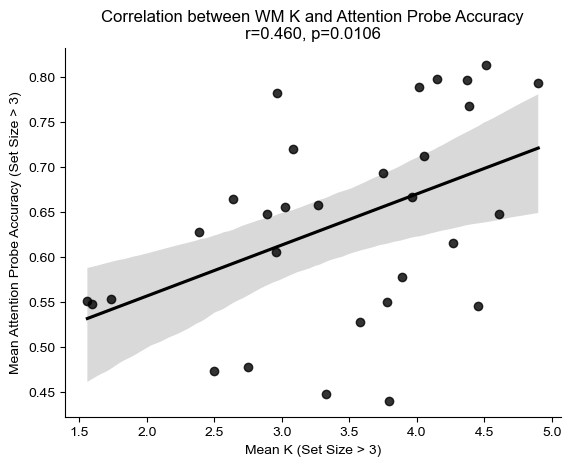

In [34]:
from scipy.stats import pearsonr

corr_res = pearsonr(sub_ks, sub_probe_accs)
corr_res
sns.regplot(x=sub_ks, y=sub_probe_accs, color="k")
plt.xlabel("Mean K (Set Size > 3)")
plt.ylabel("Mean Attention Probe Accuracy (Set Size > 3)")
plt.title(f"Correlation between WM K and Attention Probe Accuracy\nr={corr_res[0]:.3f}, p={corr_res[1]:.4f}")
sns.despine()
plt.savefig("figures/correlation_K_probe_accuracy.png", dpi=300, bbox_inches="tight", transparent=True)

# Effort Ratings

In [35]:
from collections import defaultdict

conditions = [
    "COLORS: 0",
    "COLORS: 1",
    "COLORS: 2",
    "COLORS: 3",
    "COLORS: 4",
    "COLORS: 6",
    "COLORS: 8",
    "DIGITS: 0",
    "DIGITS: 1",
    "DIGITS: 2",
    "DIGITS: 3",
    "DIGITS: 4",
    "DIGITS: 6",
    "DIGITS: 8",
]
setsize_map = {cond: int(cond[-1]) for cond in conditions}
task_map = {cond: cond.split(":")[0].lower() for cond in conditions}

In [36]:
all_effort = defaultdict(list)
for isub in ta.tqdm(range(wrangl.nsub)):
    all_effort["subject"].append(wrangl.subs[isub])

    # Load the data
    basepath = "/".join(
        str(wrangl.bids_path.copy().update(subject=wrangl.subs[isub], datatype="beh").fpath).split("/")[:-1]
    )
    effort_file = path.join(basepath, f"{wrangl.subs[isub]}_effort.json")
    with open(effort_file, "r") as f:
        sub_data = json.load(f)

    slider_min = sub_data["slider_min"]
    slider_max = sub_data["slider_max"]
    for cond in conditions:
        cond_effort = sub_data[cond]
        # rescale to 0-1
        cond_effort = (cond_effort - slider_min) / (slider_max - slider_min)
        all_effort[cond].append(cond_effort)

  0%|          | 0/34 [00:00<?, ?it/s]

In [37]:
effort_data = pd.DataFrame(all_effort).melt(var_name="condition", value_name="Effort Rating", id_vars="subject")
effort_data["Set Size"] = effort_data["condition"].map(setsize_map)
effort_data["task"] = effort_data["condition"].map(task_map)

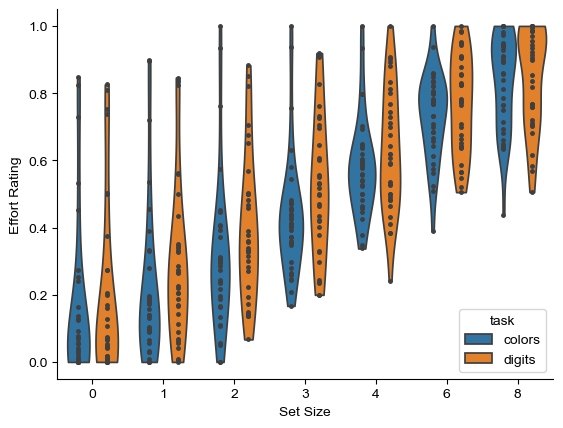

In [38]:
_ = sns.violinplot(data=effort_data, x="Set Size", y="Effort Rating", hue="task", cut=0, inner="point")
_ = sns.despine()

In [39]:
effort_data_long = effort_data.pivot(index="subject", columns="condition", values="Effort Rating")
effort_data_long.to_csv("behavior_files/effort_ratings_by_condition.csv", index=True)

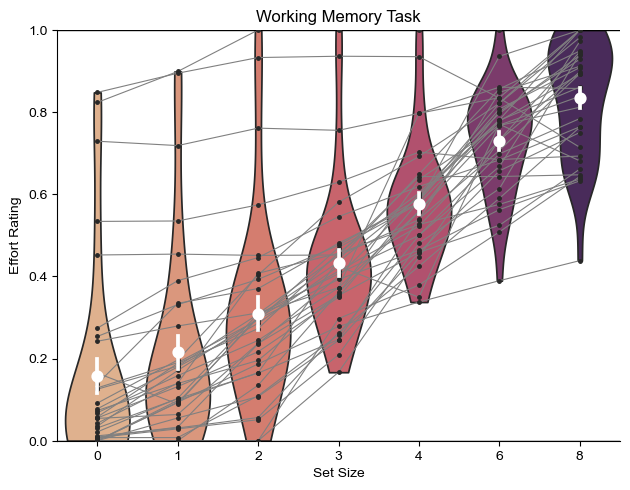

In [40]:
colors_df = effort_data[effort_data["task"] == "colors"]

ax = sns.violinplot(
    data=colors_df, x="Set Size", y="Effort Rating", inner="point", hue="Set Size", cut=0, palette="flare"
)  # palette="light:0.2")

# Draw lines connecting datapoints for each participant
for subject, sub_df in colors_df.groupby("subject"):
    sub_df.loc[:, "Set Size"] = [0, 1, 2, 3, 4, 5, 6]  # makes them increase linearly to match x-axis of violinplot
    plt.plot(sub_df["Set Size"], sub_df["Effort Rating"], color="gray", linewidth=0.8)
    # ax = sns.scatterplot(data=sub_df, x="Set Size", y="Effort Rating", color="k", zorder=10)

_ = sns.pointplot(
    data=colors_df, x="Set Size", y="Effort Rating", color="w", linestyle="none", zorder=100, errorbar="se"
)

# add horizontal lines at y=0, y=1
plt.axhline(0, color="black", linestyle="-", linewidth=1)
plt.axhline(1, color="black", linestyle="-", linewidth=1)

sns.despine()
plt.tight_layout()
# remove legend
ax.get_legend().remove()
plt.ylim(0, 1)
plt.title("Working Memory Task")
plt.savefig("figures/behavioral_effort_ratings_WM.png", dpi=300, bbox_inches="tight", transparent=True)
plt.show()

RM-ANOVA (colors effort):


/opt/homebrew/Caskroom/miniforge/base/envs/preproc_pype/lib/python3.12/site-packages/pingouin/pairwise.py:28: UserWarning: pairwise_ttests is deprecated, use pairwise_tests instead.
  warnings.warn("pairwise_ttests is deprecated, use pairwise_tests instead.", UserWarning)


,Source,ddof1,ddof2,F,p-unc,ng2,eps
0,Set Size,6,198,156.882743,2.004996e-72,0.616351,0.233791


Pairwise t-tests (Bonferroni):


,Contrast,A,B,Paired,Parametric,T,dof,alternative,p-unc,p-corr,p-adjust,BF10,hedges
0,Set Size,0,1,True,True,-6.223943,33.0,two-sided,4.998575e-07,1.049701e-05,bonf,3.318e+04,-0.238618
1,Set Size,0,2,True,True,-9.534939,33.0,two-sided,5.262243e-11,1.105071e-09,bonf,1.861e+08,-0.640904
2,Set Size,0,3,True,True,-13.675826,33.0,two-sided,3.776607e-15,7.930876e-14,bonf,1.702e+12,-1.283776
3,Set Size,0,4,True,True,-15.871558,33.0,two-sided,5.216846e-17,1.095538e-15,bonf,1.043e+14,-2.092270
4,Set Size,0,6,True,True,-15.053828,33.0,two-sided,2.432694e-16,5.108657e-15,bonf,2.372e+13,-2.949539
5,Set Size,0,8,True,True,-13.965888,33.0,two-sided,2.086259e-15,4.381144e-14,bonf,3.009e+12,-3.390796
6,Set Size,1,2,True,True,-7.795983,33.0,two-sided,5.532577e-09,1.161841e-07,bonf,2.264e+06,-0.400862
7,Set Size,1,3,True,True,-12.508366,33.0,two-sided,4.516888e-14,9.485465e-13,bonf,1.575e+11,-1.023379
8,Set Size,1,4,True,True,-14.131827,33.0,two-sided,1.491592e-15,3.132343e-14,bonf,4.152e+12,-1.820333
9,Set Size,1,6,True,True,-14.123301,33.0,two-sided,1.517424e-15,3.186591e-14,bonf,4.084e+12,-2.676164


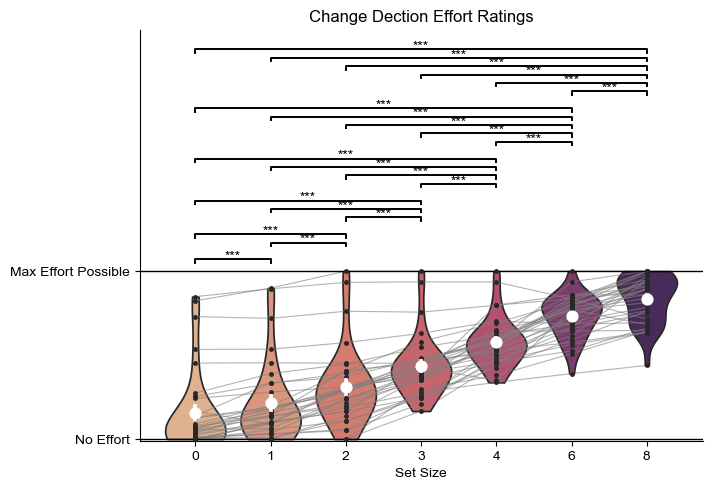

In [41]:
# Repeat the WM effort plot ("colors") with ANOVA, pairwise tests, and one-sample t-test markers

colors_df = effort_data[effort_data["task"] == "colors"].copy()
set_order = [0, 1, 2, 3, 4, 6, 8]
loc_map = {ss: i for i, ss in enumerate(set_order)}

# Stats: RM-ANOVA + pairwise comparisons
aov_effort_colors = pg.rm_anova(data=colors_df, dv="Effort Rating", within="Set Size", subject="subject")
pairwise_effort_colors = pg.pairwise_ttests(
    data=colors_df, dv="Effort Rating", within="Set Size", subject="subject", padjust="bonf"
)

print("RM-ANOVA (colors effort):")
display(aov_effort_colors)

print("Pairwise t-tests (Bonferroni):")
display(pairwise_effort_colors)


# Plot
ax = sns.violinplot(
    data=colors_df,
    x="Set Size",
    y="Effort Rating",
    inner="point",
    hue="Set Size",
    cut=0,
    palette="flare",
    order=set_order,
)

for sub, sub_df in colors_df.groupby("subject"):
    sub_df = sub_df.sort_values("Set Size")
    xvals = sub_df["Set Size"].map(loc_map).values
    plt.plot(xvals, sub_df["Effort Rating"].values, color="gray", linewidth=0.8, alpha=0.6)

_ = sns.pointplot(
    data=colors_df, x="Set Size", y="Effort Rating", color="w", linestyle="none", zorder=100, errorbar="se"
)


# Pairwise significance bars (p-corr < .05)
sig_df = pairwise_effort_colors.loc[pairwise_effort_colors["p-corr"] < 0.05, ["A", "B", "p-corr"]].copy()
if len(sig_df) > 0:
    sig_df["A"] = sig_df["A"].astype(int)
    sig_df["B"] = sig_df["B"].astype(int)
    sig_df["x1"] = sig_df["A"].map(loc_map)
    sig_df["x2"] = sig_df["B"].map(loc_map)
    sig_df = sig_df.dropna(subset=["x1", "x2"]).copy()

    sig_df[["x1", "x2"]] = np.sort(sig_df[["x1", "x2"]].values, axis=1)
    sig_df["left"] = sig_df["x1"]
    sig_df["right"] = sig_df["x2"]

    right_order = sorted(sig_df["right"].unique())
    sig_df["level"] = np.nan
    next_base_level = 0
    for r in right_order:
        idx = sig_df.index[sig_df["right"] == r]
        idx_sorted = sig_df.loc[idx].sort_values("left", ascending=False).index.tolist()
        for j, row_idx in enumerate(idx_sorted):
            sig_df.loc[row_idx, "level"] = next_base_level + j
        next_base_level += len(idx_sorted) + 1
    sig_df["level"] = sig_df["level"].astype(int)

    y_min, y_max = colors_df["Effort Rating"].min(), colors_df["Effort Rating"].max()
    y_range = y_max - y_min if y_max > y_min else 1.0
    y_base = y_max + 0.05 * y_range
    level_step = 0.05 * y_range
    h = 0.02 * y_range

    for _, row in sig_df.iterrows():
        x1, x2 = row["x1"], row["x2"]
        y = y_base + row["level"] * level_step
        p_val = row["p-corr"]

        ax.plot([x1, x1, x2, x2], [y, y + h, y + h, y], lw=1.4, c="k")
        stars = "***" if p_val < 0.001 else "**" if p_val < 0.01 else "*"
        ax.text((x1 + x2) / 2, y, stars, ha="center", va="bottom", color="k", fontsize=10)


plt.axhline(0, color="black", linestyle="-", linewidth=1)
plt.axhline(1, color="black", linestyle="-", linewidth=1)

sns.despine()
plt.tight_layout()
plt.title("Change Dection Effort Ratings")
plt.ylim(-0.01, max(1.05, ax.get_ylim()[1]))
plt.yticks([0, 1], labels=["No Effort", "Max Effort Possible"])
plt.ylabel("")
plt.legend([], [], frameon=False)
plt.savefig("figures/behavioral_effort_ratings_WM_with_stats.png", dpi=300, bbox_inches="tight", transparent=True)
plt.show()

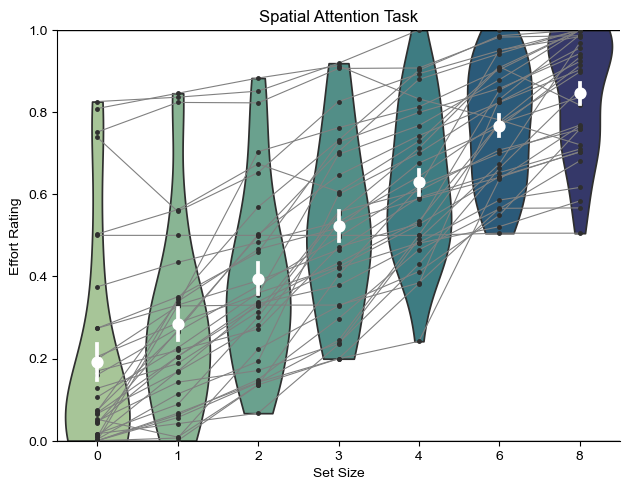

In [56]:
digits_df = effort_data[effort_data["task"] == "digits"]

ax = sns.violinplot(
    data=digits_df, x="Set Size", y="Effort Rating", inner="point", hue="Set Size", cut=0, palette="crest"
)  # palette="light:0.2")

# Draw lines connecting datapoints for each participant
for subject, sub_df in digits_df.groupby("subject"):
    sub_df.loc[:, "Set Size"] = [0, 1, 2, 3, 4, 5, 6]  # makes them increase linearly to match x-axis of violinplot
    plt.plot(sub_df["Set Size"], sub_df["Effort Rating"], color="gray", linewidth=0.8)
    # ax = sns.scatterplot(data=sub_df, x="Set Size", y="Effort Rating", color="k", zorder=10)

_ = sns.pointplot(
    data=digits_df, x="Set Size", y="Effort Rating", color="w", linestyle="none", zorder=100, errorbar="se"
)

# add horizontal lines at y=0, y=1
plt.axhline(0, color="black", linestyle="-", linewidth=1)
plt.axhline(1, color="black", linestyle="-", linewidth=1)

sns.despine()
plt.tight_layout()
# remove legend
ax.get_legend().remove()
plt.ylim(0, 1)
plt.title("Spatial Attention Task")
plt.savefig("figures/behavioral_effort_ratings_spatial_attention.png", dpi=300, bbox_inches="tight", transparent=True)

/opt/homebrew/Caskroom/miniforge/base/envs/preproc_pype/lib/python3.12/site-packages/pingouin/pairwise.py:28: UserWarning: pairwise_ttests is deprecated, use pairwise_tests instead.
  warnings.warn("pairwise_ttests is deprecated, use pairwise_tests instead.", UserWarning)


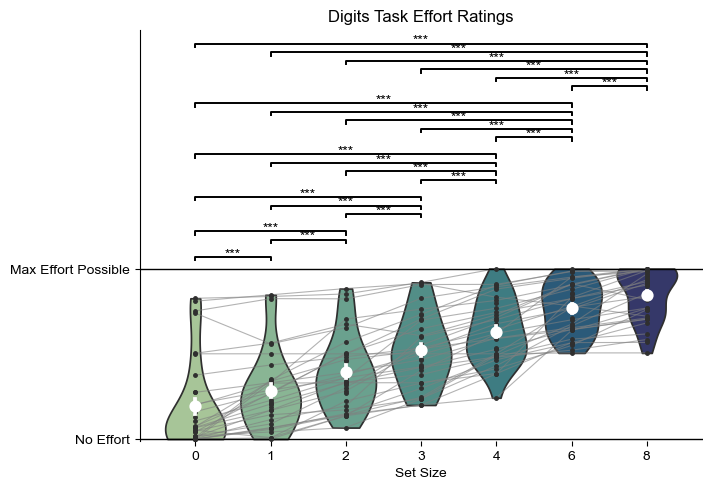

In [43]:
# Digits effort ratings with significance markers

digits_df = effort_data[effort_data["task"] == "digits"].copy()
set_order = [0, 1, 2, 3, 4, 6, 8]
loc_map = {ss: i for i, ss in enumerate(set_order)}

aov_effort_digits = pg.rm_anova(data=digits_df, dv="Effort Rating", within="Set Size", subject="subject")
pairwise_effort_digits = pg.pairwise_ttests(
    data=digits_df, dv="Effort Rating", within="Set Size", subject="subject", padjust="bonf"
)

ax = sns.violinplot(
    data=digits_df,
    x="Set Size",
    y="Effort Rating",
    inner="point",
    hue="Set Size",
    cut=0,
    palette="crest",
    order=set_order,
)

for sub, sub_df in digits_df.groupby("subject"):
    if (sub not in rejected_subs) and (sub not in split_sess_subs.values()):
        sub_df = sub_df.sort_values("Set Size")
        xvals = sub_df["Set Size"].map(loc_map).values
        plt.plot(xvals, sub_df["Effort Rating"].values, color="gray", linewidth=0.8, alpha=0.6)

_ = sns.pointplot(
    data=digits_df, x="Set Size", y="Effort Rating", color="w", linestyle="none", zorder=100, errorbar="se"
)


sig_df = pairwise_effort_digits.loc[pairwise_effort_digits["p-corr"] < 0.05, ["A", "B", "p-corr"]].copy()
if len(sig_df) > 0:
    sig_df["A"] = sig_df["A"].astype(int)
    sig_df["B"] = sig_df["B"].astype(int)
    sig_df["x1"] = sig_df["A"].map(loc_map)
    sig_df["x2"] = sig_df["B"].map(loc_map)
    sig_df = sig_df.dropna(subset=["x1", "x2"]).copy()

    sig_df[["x1", "x2"]] = np.sort(sig_df[["x1", "x2"]].values, axis=1)
    sig_df["left"] = sig_df["x1"]
    sig_df["right"] = sig_df["x2"]

    right_order = sorted(sig_df["right"].unique())
    sig_df["level"] = np.nan
    next_base_level = 0
    for r in right_order:
        idx = sig_df.index[sig_df["right"] == r]
        idx_sorted = sig_df.loc[idx].sort_values("left", ascending=False).index.tolist()
        for j, row_idx in enumerate(idx_sorted):
            sig_df.loc[row_idx, "level"] = next_base_level + j
        next_base_level += len(idx_sorted) + 1
    sig_df["level"] = sig_df["level"].astype(int)

    y_min, y_max = digits_df["Effort Rating"].min(), digits_df["Effort Rating"].max()
    y_range = y_max - y_min if y_max > y_min else 1.0
    y_base = y_max + 0.05 * y_range
    level_step = 0.05 * y_range
    h = 0.02 * y_range

    for _, row in sig_df.iterrows():
        x1, x2 = row["x1"], row["x2"]
        y = y_base + row["level"] * level_step
        p_val = row["p-corr"]

        ax.plot([x1, x1, x2, x2], [y, y + h, y + h, y], lw=1.4, c="k")
        stars = "***" if p_val < 0.001 else "**" if p_val < 0.01 else "*"
        ax.text((x1 + x2) / 2, y, stars, ha="center", va="bottom", color="k", fontsize=10)

    top_y = y_base + sig_df["level"].max() * level_step + h
    ax.set_ylim(y_min - 0.02 * y_range, top_y + 0.08 * y_range)

plt.axhline(0, color="black", linestyle="-", linewidth=1)
plt.axhline(1, color="black", linestyle="-", linewidth=1)
sns.despine(bottom=True)
plt.tight_layout()
ax.get_legend().remove()
plt.ylim(-0.01, max(1.05, ax.get_ylim()[1]))
plt.yticks([0, 1], labels=["No Effort", "Max Effort Possible"])
plt.ylabel("")
plt.title("Digits Task Effort Ratings")
plt.savefig("figures/behavioral_effort_ratings_digits_with_stats.png", dpi=300, bbox_inches="tight", transparent=True)
plt.show()

# Change Localization data

In [44]:
import ast

In [45]:
change_loc_res = defaultdict(list)
change_loc_files = sorted(glob("../change_localization_data/*.csv"))
for f in change_loc_files:
    sub_df = pd.read_csv(f)
    sub_code = ast.literal_eval(sub_df.loc[1, "response"])["Q0"]
    if "banyan2" in sub_code.lower():
        subid = sub_code.split("_")[1]
        if subid in rejected_subs:
            print(f"Skipping {subid} for change localization analysis, was rejected for behavioral analyses")
            continue

        print(f"Subject ID: {subid}")
        sub_changeLoc_df = sub_df.loc[3:]
        if subid in split_sess_subs.keys():
            second_sess_id = split_sess_subs[subid]
            print(f"concatenating change localization data for {second_sess_id} onto {subid}")
            second_sess_file = f.replace(subid, second_sess_id)
            sub_changeLoc_df_2 = pd.read_csv(second_sess_file).loc[3:]
            sub_changeLoc_df = pd.concat([sub_changeLoc_df, sub_changeLoc_df_2], axis=0).reset_index(drop=True)

        if subid in split_sess_subs.values():
            print(f"Skipping {subid} for change localization analysis, was concatenated onto another subject ID")
            continue

        change_loc_res["subject"].append(subid)
        sub_acc = np.mean(sub_changeLoc_df["accuracy"].astype(float).values)
        change_loc_res["accuracy"].append(sub_acc)
        change_loc_res["K"].append(((sub_acc) * 36 - 6) / 5)  # K formula for change localization with 6 items

Subject ID: 01
Subject ID: 02
Subject ID: 03
Subject ID: 04
Subject ID: 05
Subject ID: 06
Subject ID: 07
Subject ID: 08
Subject ID: 09
Subject ID: 10
Subject ID: 11
Subject ID: 12
Subject ID: 13
Subject ID: 14
Subject ID: 15
Subject ID: 16
Subject ID: 17
Subject ID: 18
Skipping 19 for change localization analysis, was rejected for behavioral analyses
Subject ID: 20
Subject ID: 21
Subject ID: 22
concatenating change localization data for 34 onto 22
Subject ID: 23
Subject ID: 25
Subject ID: 26
Subject ID: 27
Subject ID: 28
Subject ID: 30
Subject ID: 31
Skipping 32 for change localization analysis, was rejected for behavioral analyses
Skipping 33 for change localization analysis, was rejected for behavioral analyses
Subject ID: 34
Skipping 34 for change localization analysis, was concatenated onto another subject ID
Subject ID: 35
Subject ID: 36


In [46]:
# k_dict = {sub: k for sub, k in zip(change_loc_res["subject"], change_loc_res["K"])}
# with open("k_estimates.json", "w") as f:
#     json.dump(k_dict, f)

In [47]:
change_loc_df = pd.DataFrame(change_loc_res)
median_k = change_loc_df.K.median()
high_k_subs = change_loc_df[change_loc_df.K > median_k]["subject"].values
low_k_subs = change_loc_df[change_loc_df.K <= median_k]["subject"].values
k_sub_map = {sub: "high_K" if sub in high_k_subs else "low_K" for sub in change_loc_df["subject"].values}
k_sub_map

{'01': 'high_K',
 '02': 'low_K',
 '03': 'low_K',
 '04': 'low_K',
 '05': 'low_K',
 '06': 'low_K',
 '07': 'high_K',
 '08': 'low_K',
 '09': 'high_K',
 '10': 'low_K',
 '11': 'low_K',
 '12': 'low_K',
 '13': 'high_K',
 '14': 'low_K',
 '15': 'low_K',
 '16': 'low_K',
 '17': 'low_K',
 '18': 'high_K',
 '20': 'high_K',
 '21': 'high_K',
 '22': 'high_K',
 '23': 'high_K',
 '25': 'low_K',
 '26': 'high_K',
 '27': 'low_K',
 '28': 'low_K',
 '30': 'high_K',
 '31': 'high_K',
 '35': 'high_K',
 '36': 'high_K'}

In [48]:
change_loc_df.K.mean()

np.float64(2.7159999999999993)

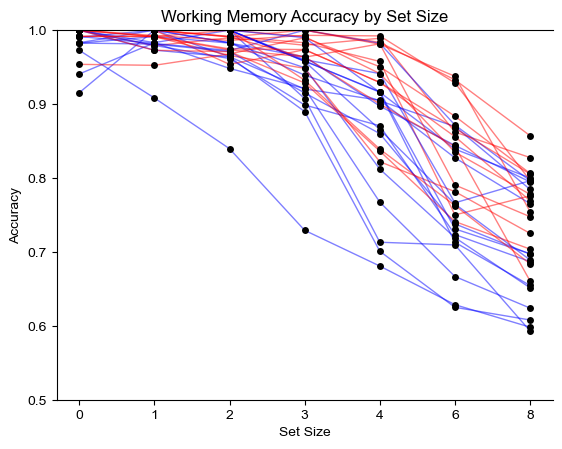

In [49]:
acc_df["K_group"] = acc_df["Subject"].map(k_sub_map)

# plot strip plots of participants at each set size
ax = sns.stripplot(data=acc_df, x="Set Size", y="Accuracy", color="k", alpha=1, jitter=False, size=5)

for sub in wrangl.subs:
    if (sub not in rejected_subs) and (sub not in split_sess_subs.values()):
        sub_data = acc_df.query(f"Subject=='{sub}'")
        plt.plot(
            [0, 1, 2, 3, 4, 5, 6],  # hack to get the x positions of the violin/strip plots
            sub_data["Accuracy"],
            color="red" if k_sub_map[sub] == "high_K" else "blue",
            alpha=0.5,
            linewidth=1,
        )

plt.title("Working Memory Accuracy by Set Size")
ax.set_ylim(0.5, 1)
sns.despine(right=True, top=False)
plt.show()

In [50]:
sub_data

,Set Size,Subject,Accuracy,K_group
203,0,36,1.000000,high_K
204,1,36,1.000000,high_K
205,2,36,0.990909,high_K
206,3,36,0.963303,high_K
207,4,36,0.981481,high_K
208,6,36,0.790476,high_K
209,8,36,0.747573,high_K


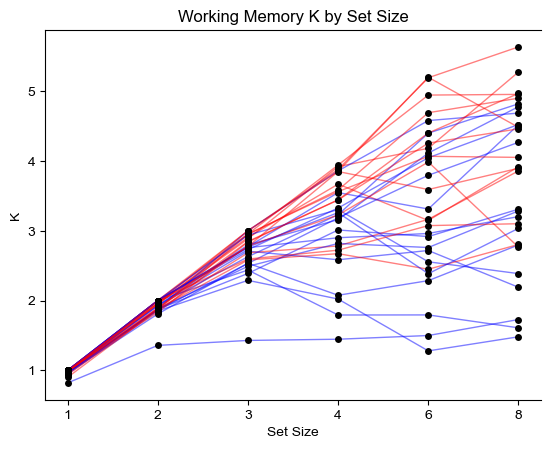

In [51]:
ax = sns.stripplot(data=k_df, x="Set Size", y="K", color="k", alpha=1, jitter=False, size=5)

for sub in wrangl.subs:
    if (sub not in rejected_subs) and (sub not in split_sess_subs.values()):
        sub_data = k_df.query(f"Subject=='{sub}'")
        plt.plot(
            [0, 1, 2, 3, 4, 5],  # hack to get the x positions of the violin/strip plots
            sub_data["K"],
            color="red" if k_sub_map[sub] == "high_K" else "blue",
            alpha=0.5,
            linewidth=1,
        )

plt.title("Working Memory K by Set Size")
sns.despine(right=True, top=False)
plt.show()

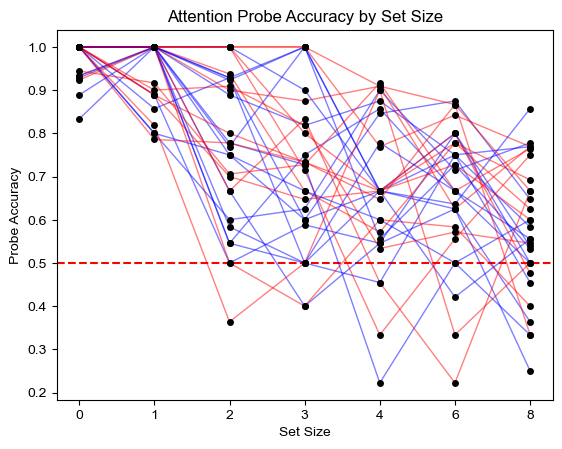

In [52]:
ax = sns.stripplot(data=probe_accs_df, x="Set Size", y="Probe Accuracy", color="k", alpha=1, jitter=False, size=5)
for sub in wrangl.subs:
    if (sub not in rejected_subs) and (sub not in split_sess_subs.values()):
        sub_data = probe_accs_df.query(f"Subject=='{sub}'")
        plt.plot(
            [0, 1, 2, 3, 4, 5, 6],  # hack to get the x positions of the violin/strip plots
            sub_data["Probe Accuracy"],
            color="red" if k_sub_map[sub] == "high_K" else "blue",
            alpha=0.5,
            linewidth=1,
        )
_ = plt.axhline(0.5, color="r", linestyle="--", label="Chance Level", zorder=-1)
plt.title("Attention Probe Accuracy by Set Size")
plt.show()

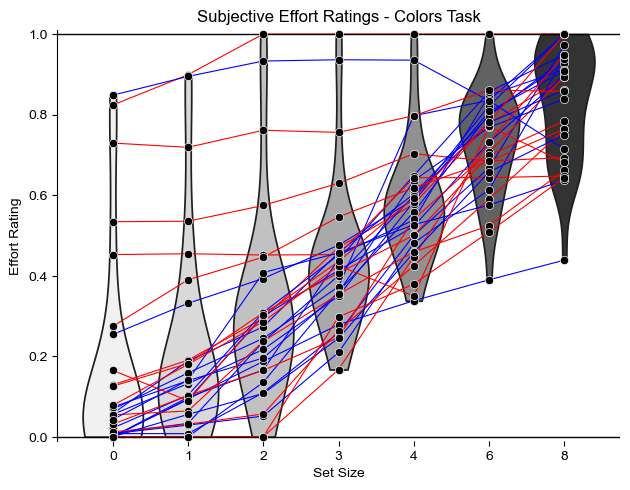

In [53]:
colors_df = effort_data[effort_data["task"] == "colors"]

sns.violinplot(data=colors_df, x="Set Size", y="Effort Rating", inner=None, hue="Set Size", cut=0, palette="light:0.2")

# Draw lines connecting datapoints for each participant
for sub, sub_df in colors_df.groupby("subject"):
    if (sub not in rejected_subs) and (sub not in split_sess_subs.values()):
        sub_df.loc[:, "Set Size"] = [0, 1, 2, 3, 4, 5, 6]  # makes them increase linearly to match x-axis of violinplot
        plt.plot(
            sub_df["Set Size"],
            sub_df["Effort Rating"],
            color="red" if k_sub_map[sub] == "high_K" else "blue",
            linewidth=0.8,
        )
        ax = sns.scatterplot(data=sub_df, x="Set Size", y="Effort Rating", color="k", zorder=10)

# add horizontal lines at y=0, y=1
plt.axhline(0, color="black", linestyle="-", linewidth=1)
plt.axhline(1, color="black", linestyle="-", linewidth=1)

sns.despine(bottom=True)
plt.tight_layout()
# remove legend
ax.get_legend().remove()
plt.ylim(-0.01, 1.01)
plt.title("Subjective Effort Ratings - Colors Task")
plt.show()

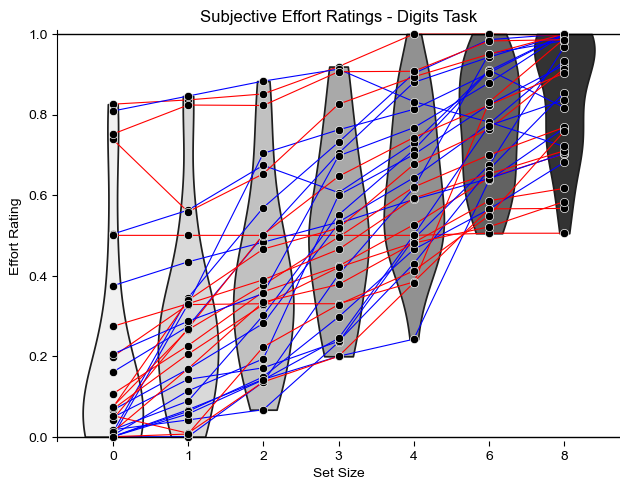

In [54]:
colors_df = effort_data[effort_data["task"] == "digits"]

sns.violinplot(data=colors_df, x="Set Size", y="Effort Rating", inner=None, hue="Set Size", cut=0, palette="light:0.2")

# Draw lines connecting datapoints for each participant
for sub, sub_df in colors_df.groupby("subject"):
    if (sub not in rejected_subs) and (sub not in split_sess_subs.values()):
        sub_df.loc[:, "Set Size"] = [0, 1, 2, 3, 4, 5, 6]  # makes them increase linearly to match x-axis of violinplot
        plt.plot(
            sub_df["Set Size"],
            sub_df["Effort Rating"],
            color="red" if k_sub_map[sub] == "high_K" else "blue",
            linewidth=0.8,
        )
        ax = sns.scatterplot(data=sub_df, x="Set Size", y="Effort Rating", color="k", zorder=10)

# add horizontal lines at y=0, y=1
plt.axhline(0, color="black", linestyle="-", linewidth=1)
plt.axhline(1, color="black", linestyle="-", linewidth=1)

sns.despine(bottom=True)
plt.tight_layout()
# remove legend
ax.get_legend().remove()
plt.ylim(-0.01, 1.01)
plt.title("Subjective Effort Ratings - Digits Task")
plt.show()